<a href="https://colab.research.google.com/github/emrizky1/machine-learning/blob/main/JS10/JS10_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

tf.random.set_seed(42)
np.random.seed(42)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 28, 28) (10000, 28, 28)


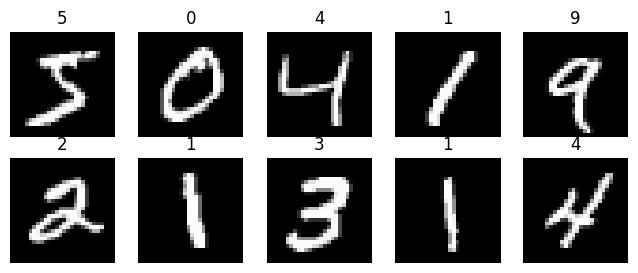

In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()
print(X_train.shape, X_test.shape)

plt.figure(figsize=(8, 3))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.show()

In [3]:
X_train = X_train / 255.0
X_test = X_test / 255.0

In [4]:
def build_model(activation='relu', units=(128, 64), dropout=0.2):
    model = models.Sequential([layers.Input(shape=(28, 28)), layers.Flatten()])
    for u in units:
        model.add(layers.Dense(u, activation=activation))
        if dropout:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model

model = build_model()
model.summary()

history = model.fit(X_train, y_train, epochs=15, batch_size=128,
                    validation_split=0.1, verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8558 - loss: 0.4786 - val_accuracy: 0.9577 - val_loss: 0.1535
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9362 - loss: 0.2149 - val_accuracy: 0.9653 - val_loss: 0.1125
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9511 - loss: 0.1636 - val_accuracy: 0.9723 - val_loss: 0.0926
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9606 - loss: 0.1320 - val_accuracy: 0.9753 - val_loss: 0.0858
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9653 - loss: 0.1134 - val_accuracy: 0.9782 - val_loss: 0.0752
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9692 - loss: 0.1017 - val_accuracy: 0.9773 - val_loss: 0.0776
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.9738 - loss: 0.0857 - val_accuracy: 0.9792 - val_loss: 0.0731
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9755 - loss: 0.0788 - val_accuracy: 0.

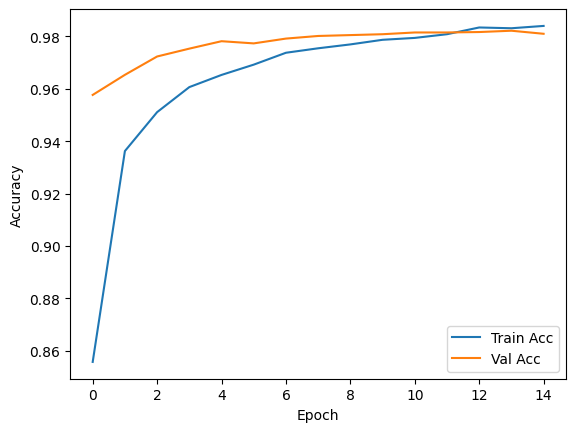

In [5]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.show()

Test accuracy: 0.9787
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.98      0.98      1032
           3       0.97      0.98      0.98      1010
           4       0.98      0.98      0.98       982
           5       0.98      0.98      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.97      0.98      1028
           8       0.97      0.97      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



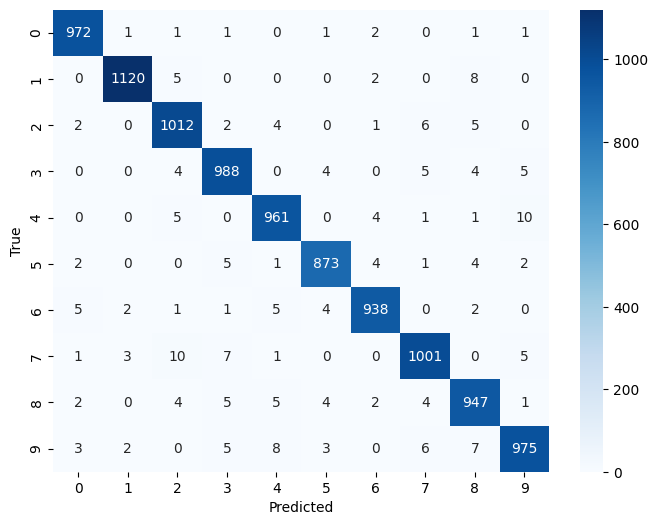

In [6]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

y_pred = np.argmax(model.predict(X_test), axis=1)
print(classification_report(y_test, y_pred))

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('True'); plt.show()

relu 128-64          test acc = 0.9790
tanh 128-64          test acc = 0.9723
sigmoid 128-64       test acc = 0.9677
relu 256-128-64      test acc = 0.9804
relu 64 (shallow)    test acc = 0.9696


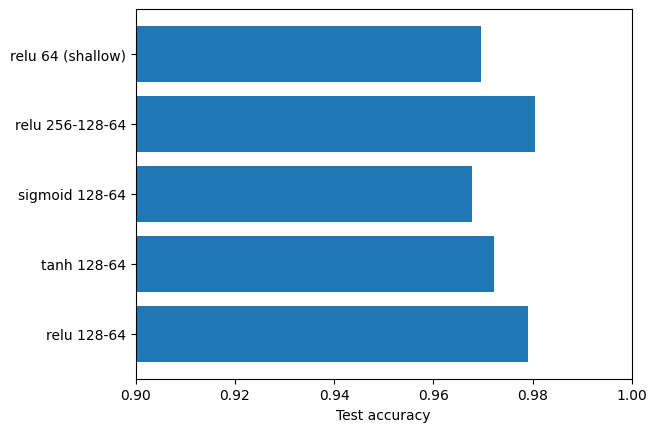

In [7]:
experiments = {
    'relu 128-64':       dict(activation='relu',    units=(128, 64)),
    'tanh 128-64':       dict(activation='tanh',    units=(128, 64)),
    'sigmoid 128-64':    dict(activation='sigmoid', units=(128, 64)),
    'relu 256-128-64':   dict(activation='relu',    units=(256, 128, 64)),
    'relu 64 (shallow)': dict(activation='relu',    units=(64,)),
}

results = {}
for name, cfg in experiments.items():
    m = build_model(**cfg)
    h = m.fit(X_train, y_train, epochs=10, batch_size=128,
              validation_split=0.1, verbose=0)
    _, acc = m.evaluate(X_test, y_test, verbose=0)
    results[name] = acc
    print(f"{name:20s} test acc = {acc:.4f}")

plt.barh(list(results.keys()), list(results.values()))
plt.xlim(0.9, 1.0); plt.xlabel('Test accuracy'); plt.show()